In [1]:
import pandas
from airpollutionforecasting.pipeline import run_pipeline
from airpollutionforecasting.config import DatasetConfig
from airpollutionforecasting.plots import draw_histogram, draw_timeseries

2026-11-01 22:52:16.138 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")

2026-11-01 22:52:16.419 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-01 22:52:16.421 | INFO     | airpollutionforecasting.data.loader:load:19 - Loading the data..
2026-11-01 22:52:16.519 | INFO     | airpollutionforecasting.data.data_validator:validate:153 - Starting data validation...
2026-11-01 22:52:16.520 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking required columns and data types...
2026-11-01 22:52:16.520 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Column and data type validation passed.
2026-11-01 22:52:16.520 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking configured date range...
2026-11-01 22:52:16.521 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:161 - Date range validation passed.
2026-11-01 22:52:16.521 | INFO     | airpollutionforecasting.data.data_validator:validate:163 - Checking for missing value

---
splitfile locations contains paths to the loaded train, validation and test sets.   
I will investigate the data with the use of the test set.

In [3]:
data = pandas.read_csv(split_files_locations[0])

In [4]:
data.head(5)

,time,air_temp,dew_point_temp,relative_humidity,air_pressure,sea_level_pressure,wind_direction,wind_speed,cloud_cover,pm_10
0,2016-01-01 00:00:00,-8.871667,-13.201667,70.875000,1000.903333,1027.875000,280.0,0.771667,0.0,313.267333
1,2016-01-01 01:00:00,-9.153333,-13.351667,71.593333,1000.516667,1027.516667,265.0,0.703333,0.0,288.007000
2,2016-01-01 02:00:00,-9.475000,-13.636667,71.685000,1000.363333,1027.363333,269.0,0.698333,0.0,298.940000
3,2016-01-01 03:00:00,-9.851667,-13.971667,71.863333,1000.123333,1027.180000,283.0,0.743333,0.0,289.741667
4,2016-01-01 04:00:00,-10.175000,-14.321667,71.668333,1000.190000,1027.290000,286.0,0.661667,0.0,296.505000


---
## Investigate the mean and std of the data

In [5]:
data.describe()

,air_temp,dew_point_temp,relative_humidity,air_pressure,sea_level_pressure,wind_direction,wind_speed,cloud_cover,pm_10
count,65352.000000,65352.000000,65352.000000,65352.000000,65352.000000,65352.000000,65352.000000,65352.000000,65352.000000
mean,10.029180,2.610924,62.781508,989.795859,1014.735838,210.425985,1.793753,33.845789,39.451567
std,8.646600,7.196413,16.119943,8.228846,8.591730,97.869899,1.157998,39.633821,32.233293
min,-20.728333,-25.405000,6.410000,718.418182,736.363636,0.000000,0.100000,0.000000,1.790875
25%,3.278333,-2.691667,51.662917,984.896667,1009.469583,102.000000,0.855000,0.000000,19.615992
50%,9.300000,2.475000,65.967500,990.095833,1014.730000,250.000000,1.565000,12.000000,30.217600
75%,16.688333,8.288750,75.815000,994.945000,1020.081667,280.000000,2.425000,74.000000,47.794017
max,35.673333,20.700000,100.000000,1017.685000,1044.400000,360.000000,11.520000,100.000000,402.945000


### Observations
Mean temperratire in Krakow in the test set is 10 witg $\sigma=8.6$, which seem reasonable.
Wind direction has quite a big std variation, this makes sense as wind direction tends to change a lot. 
**Target** that is PM10 has a mean of $\mu = 39$ and $\sigma=32$, additionally what already can be seen from the table based on quantiles and maximum values is that this data should be mostly stable (I expect it to happen during warmer part of the year) but huge outliers are present in the data. Let's check it.

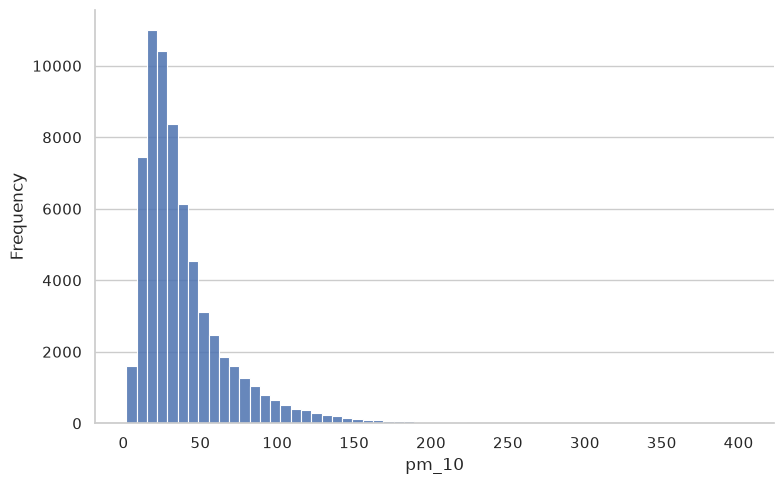

In [6]:
draw_histogram(data["pm_10"], bins=60)

### Observations
As mentioned before, histogram shows that the data is clearly right-tailed.

---
## Correlations

In [7]:
# In order to take a look at the correlation lets get the list of numerical values
config = DatasetConfig.load_config()
numeric_cols = config.numeric_cols

In [8]:
data[numeric_cols].corr()

,air_temp,dew_point_temp,relative_humidity,air_pressure,sea_level_pressure,wind_direction,wind_speed,cloud_cover,pm_10
air_temp,1.000000,0.847718,-0.456836,-0.132912,-0.222313,-0.001427,0.046503,-0.339132,-0.386207
dew_point_temp,0.847718,1.000000,0.073413,-0.163348,-0.236859,0.053223,-0.094996,-0.208935,-0.361312
relative_humidity,-0.456836,0.073413,1.000000,-0.017876,0.027953,0.081298,-0.244622,0.297970,0.124240
air_pressure,-0.132912,-0.163348,-0.017876,1.000000,0.995595,-0.024078,-0.128146,0.010156,0.139109
sea_level_pressure,-0.222313,-0.236859,0.027953,0.995595,1.000000,-0.024326,-0.125987,0.041513,0.171578
wind_direction,-0.001427,0.053223,0.081298,-0.024078,-0.024326,1.000000,-0.013150,0.012367,-0.036189
wind_speed,0.046503,-0.094996,-0.244622,-0.128146,-0.125987,-0.013150,1.000000,0.168935,-0.254733
cloud_cover,-0.339132,-0.208935,0.297970,0.010156,0.041513,0.012367,0.168935,1.000000,-0.077834
pm_10,-0.386207,-0.361312,0.124240,0.139109,0.171578,-0.036189,-0.254733,-0.077834,1.000000


### Observations
Temperature has a pretty strong correlation with `pm_10` (our target), the same goes with `wind_speed`.   
Correlation for temperature and wind speed are negative, which can make sense - higher temperature - less   
heating - less air pollution and strong wind should be able to reduce PM10 concetration as well.   
For `wind_direction` there is no correlation at all, but I will leave it due to the geographic specyfics of Krakow    
(it can be that wind in only 1 or 2 directions can influence air pollution for example).

---
## Target Investigation
The point of the project is to predict $PM_{10}$ concetration based on it's ihstorical values and other 
variables such as weather.
Let;s investigate the data that the project aims to predict.

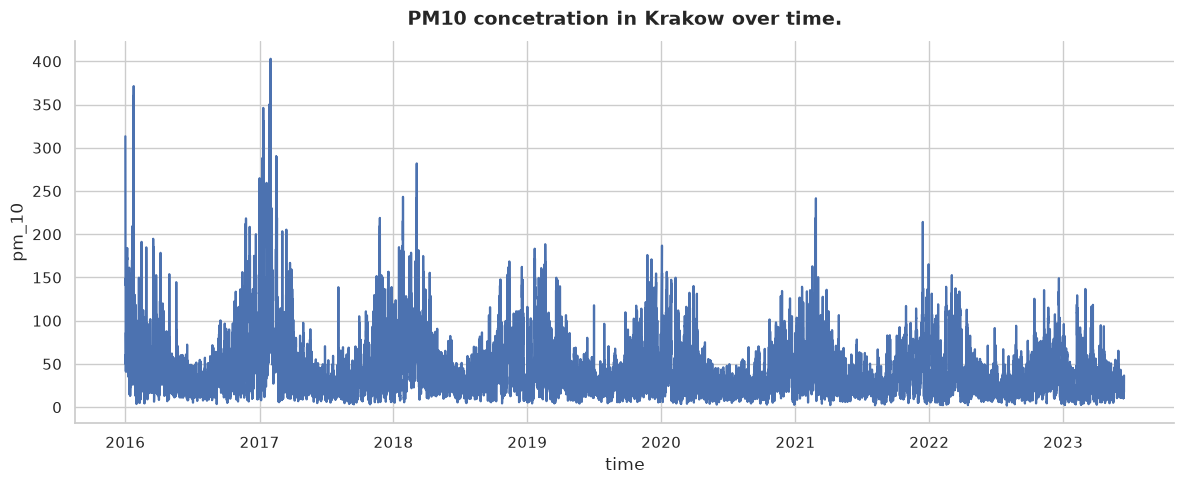

In [9]:
draw_timeseries(
    data=data, x="time", y="pm_10", title="PM10 concetration in Krakow over time."
)

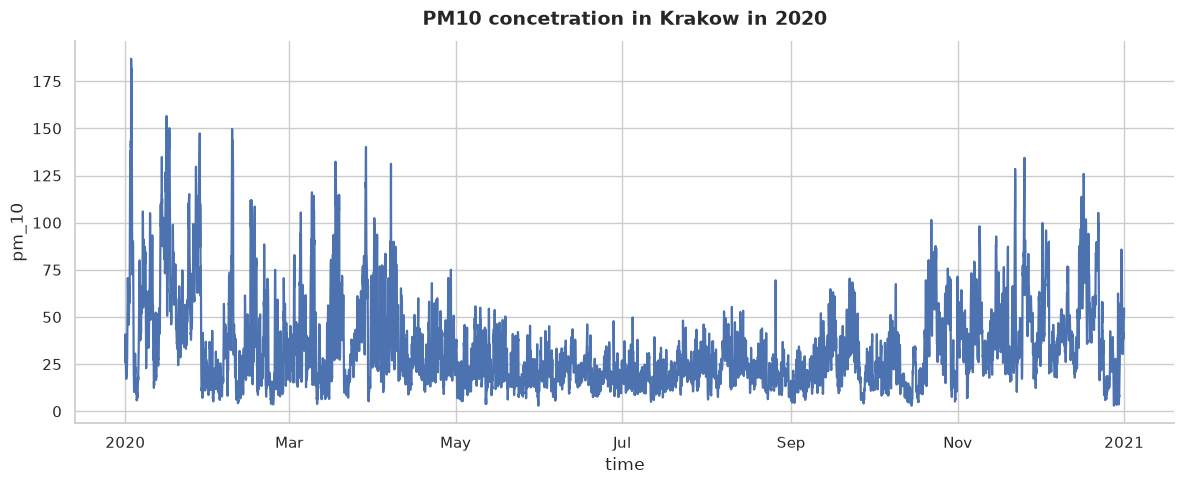

In [10]:
draw_timeseries(
    data=data,
    x="time",
    y="pm_10",
    title="PM10 concetration in Krakow in 2020",
    start="2020-01-01",
    end="2020-12-31",
)

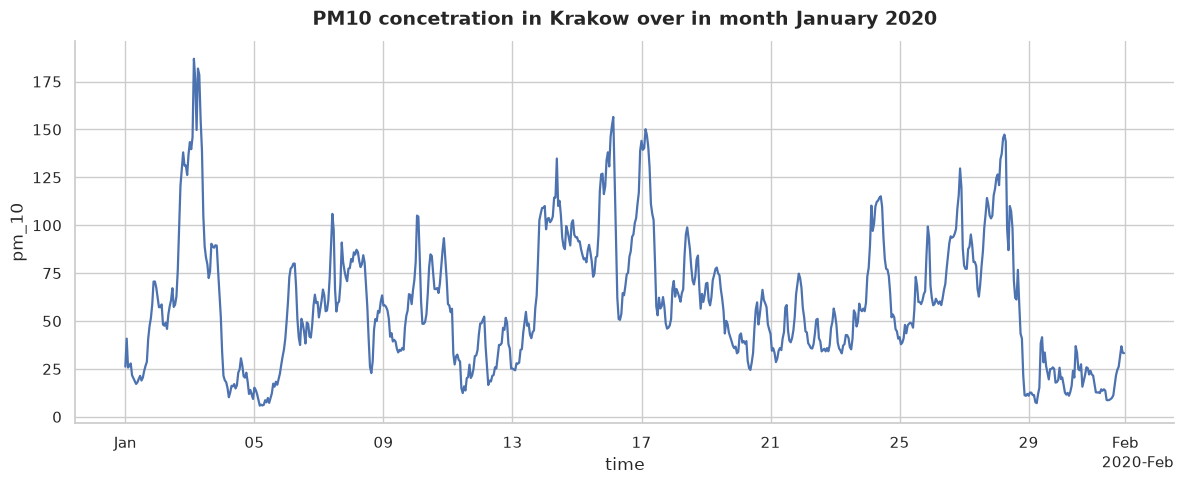

In [11]:
draw_timeseries(
    data=data,
    x="time",
    y="pm_10",
    title="PM10 concetration in Krakow over in month January 2020",
    start="2020-01-01",
    end="2020-01-31",
)

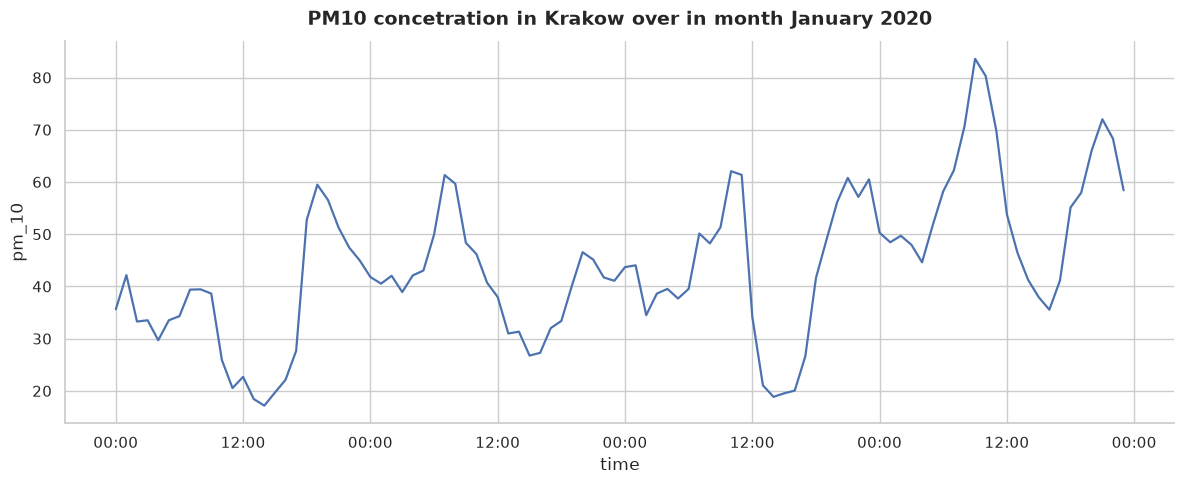

In [12]:
draw_timeseries(
    data=data,
    x="time",
    y="pm_10",
    title="PM10 concetration in Krakow over in month January 2020",
    start="2022-10-10 00:00",
    end="2022-10-13 23:00",
    date_format="%H:%M",
)

### Observations
Firstly we see that in 2016 PM10 concentrations reached higher values than more recent values.    
Secondly, clearly in winter air ppolution is higher than in summer. Additionally data is somehow periodic.
Data seems to have yearly and daily periods (at 12:00 minimum every 12 hours).  

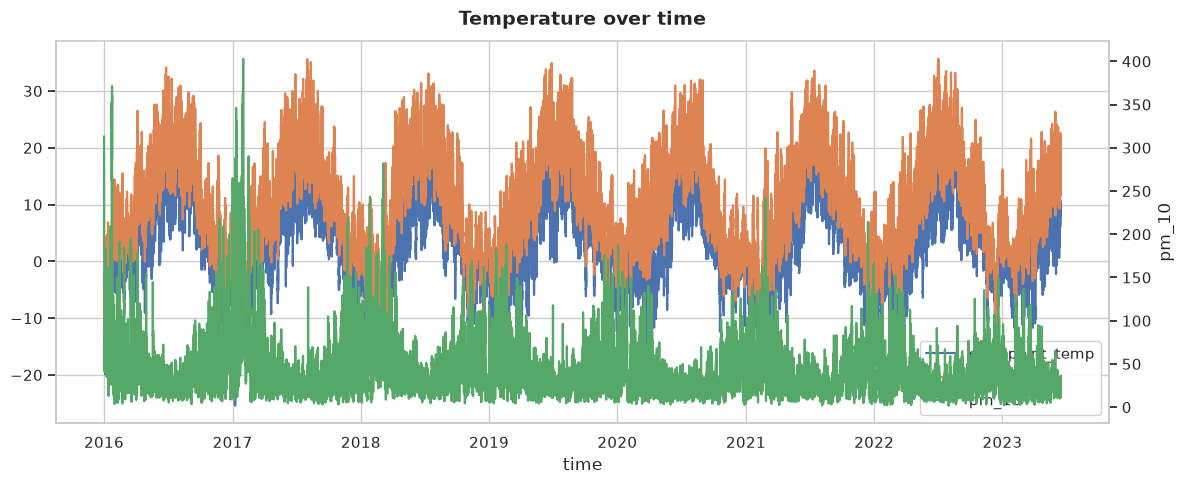

In [13]:
draw_timeseries(
    data,
    x="time",
    y=["dew_point_temp", "air_temp", "pm_10"],
    secondary_y=["pm_10"],
    title="Temperature over time",
)

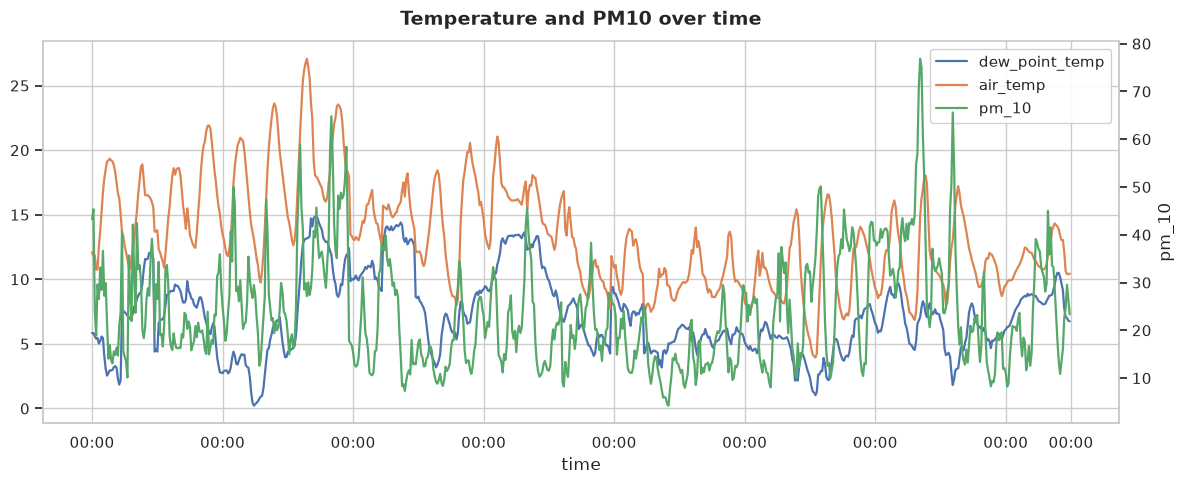

In [14]:
draw_timeseries(
    data,
    x="time",
    y=["dew_point_temp", "air_temp", "pm_10"],
    secondary_y=["pm_10"],
    title="Temperature and PM10 over time",
    start="2022-09-01 00:00",
    end="2022-09-30 23:00",
    date_format="%H:%M",
)

Clearly what the correlation said - higher temperatures corelate with lower PM10 and vice versa.

In [15]:
numeric_cols

['air_temp',
 'dew_point_temp',
 'relative_humidity',
 'air_pressure',
 'sea_level_pressure',
 'wind_direction',
 'wind_speed',
 'cloud_cover',
 'pm_10']

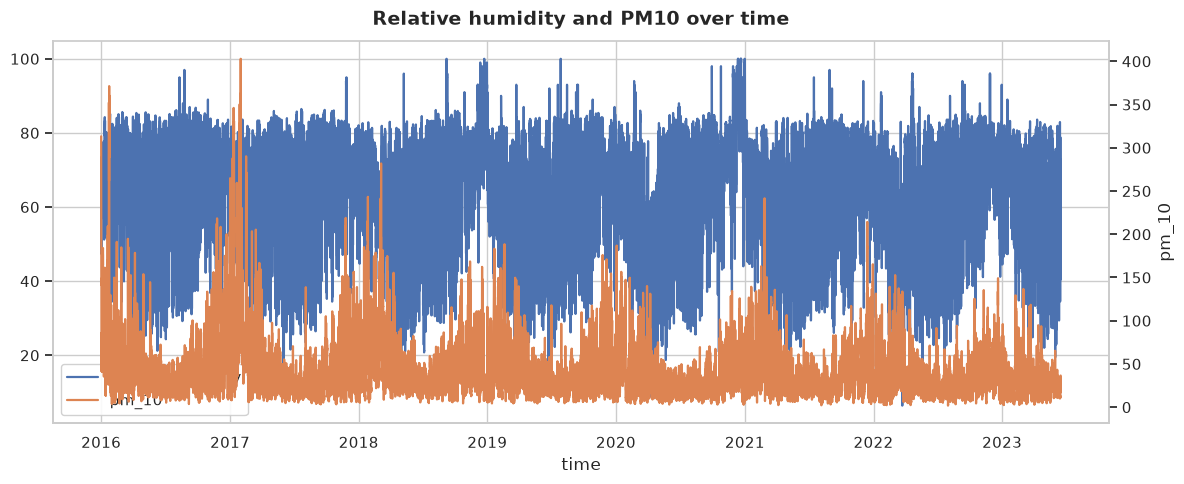

In [16]:
draw_timeseries(
    data,
    x="time",
    y=["relative_humidity", "pm_10"],
    secondary_y=["pm_10"],
    title="Relative humidity and PM10 over time",
)

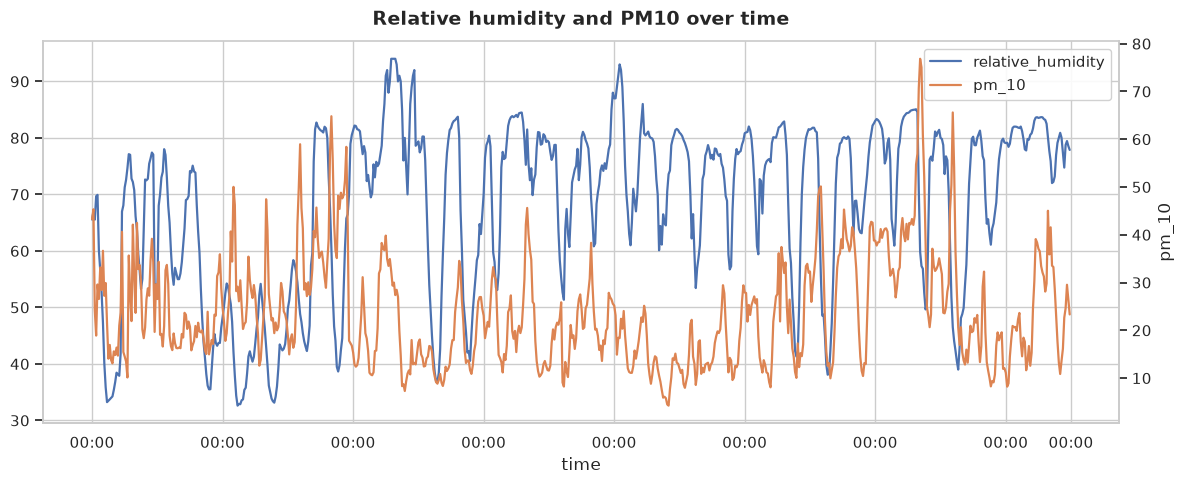

In [17]:
draw_timeseries(
    data,
    x="time",
    y=["relative_humidity", "pm_10"],
    secondary_y=["pm_10"],
    title="Relative humidity and PM10 over time",
    start="2022-09-01 00:00",
    end="2022-09-30 23:00",
    date_format="%H:%M",
)

It looks a bit (on a whole time picture) that relative humidity is somehow lagged with high PM10.

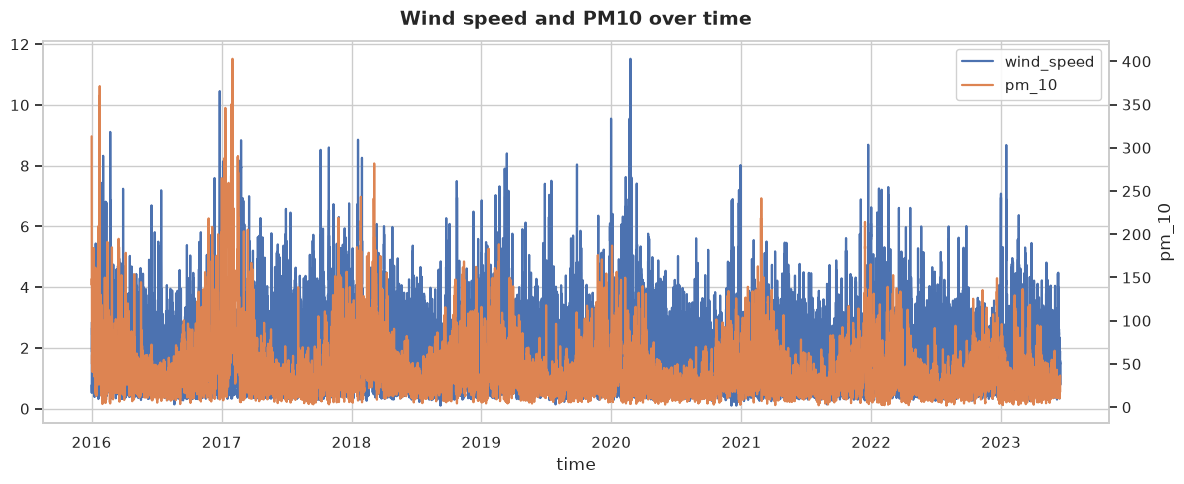

In [18]:
draw_timeseries(
    data,
    x="time",
    y=["wind_speed", "pm_10"],
    secondary_y=["pm_10"],
    title="Wind speed and PM10 over time",
)

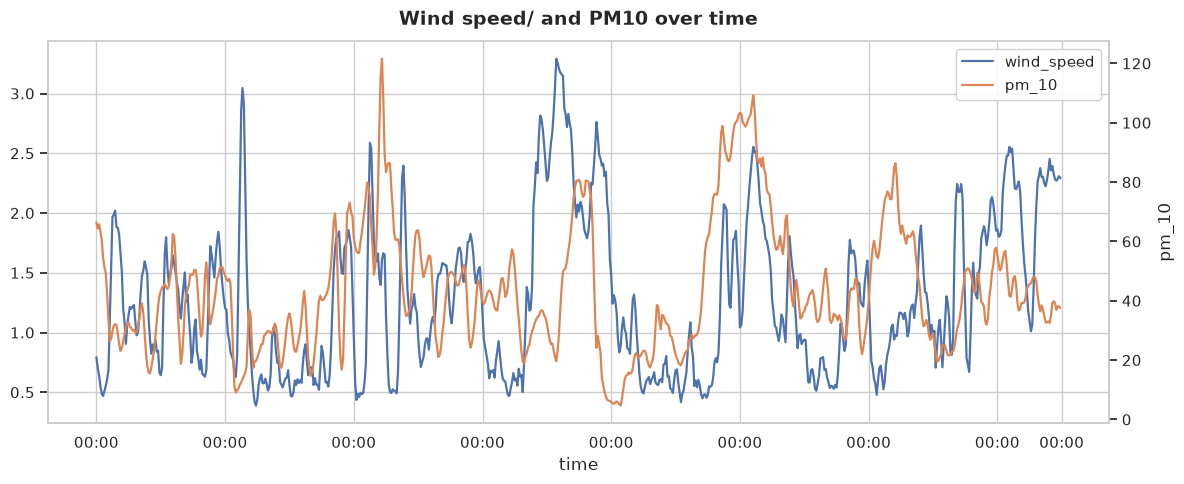

In [19]:
draw_timeseries(
    data,
    x="time",
    y=["wind_speed", "pm_10"],
    secondary_y=["pm_10"],
    title="Wind speed/ and PM10 over time",
    start="2022-11-01 00:00",
    end="2022-11-30 23:00",
    date_format="%H:%M",
    rolling=3,
)

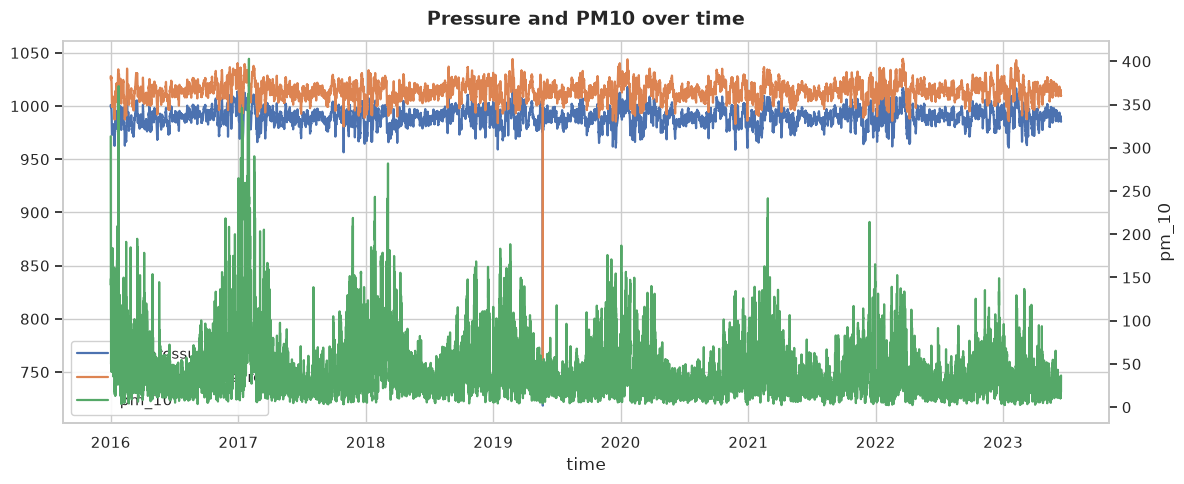

In [20]:
draw_timeseries(
    data,
    x="time",
    y=["air_pressure", "sea_level_pressure", "pm_10"],
    secondary_y=["pm_10"],
    title="Pressure and PM10 over time",
)

array([[<Axes: title={'center': 'air_temp'}>,
        <Axes: title={'center': 'dew_point_temp'}>,
        <Axes: title={'center': 'relative_humidity'}>],
       [<Axes: title={'center': 'air_pressure'}>,
        <Axes: title={'center': 'sea_level_pressure'}>,
        <Axes: title={'center': 'wind_direction'}>],
       [<Axes: title={'center': 'wind_speed'}>,
        <Axes: title={'center': 'cloud_cover'}>,
        <Axes: title={'center': 'pm_10'}>]], dtype=object)

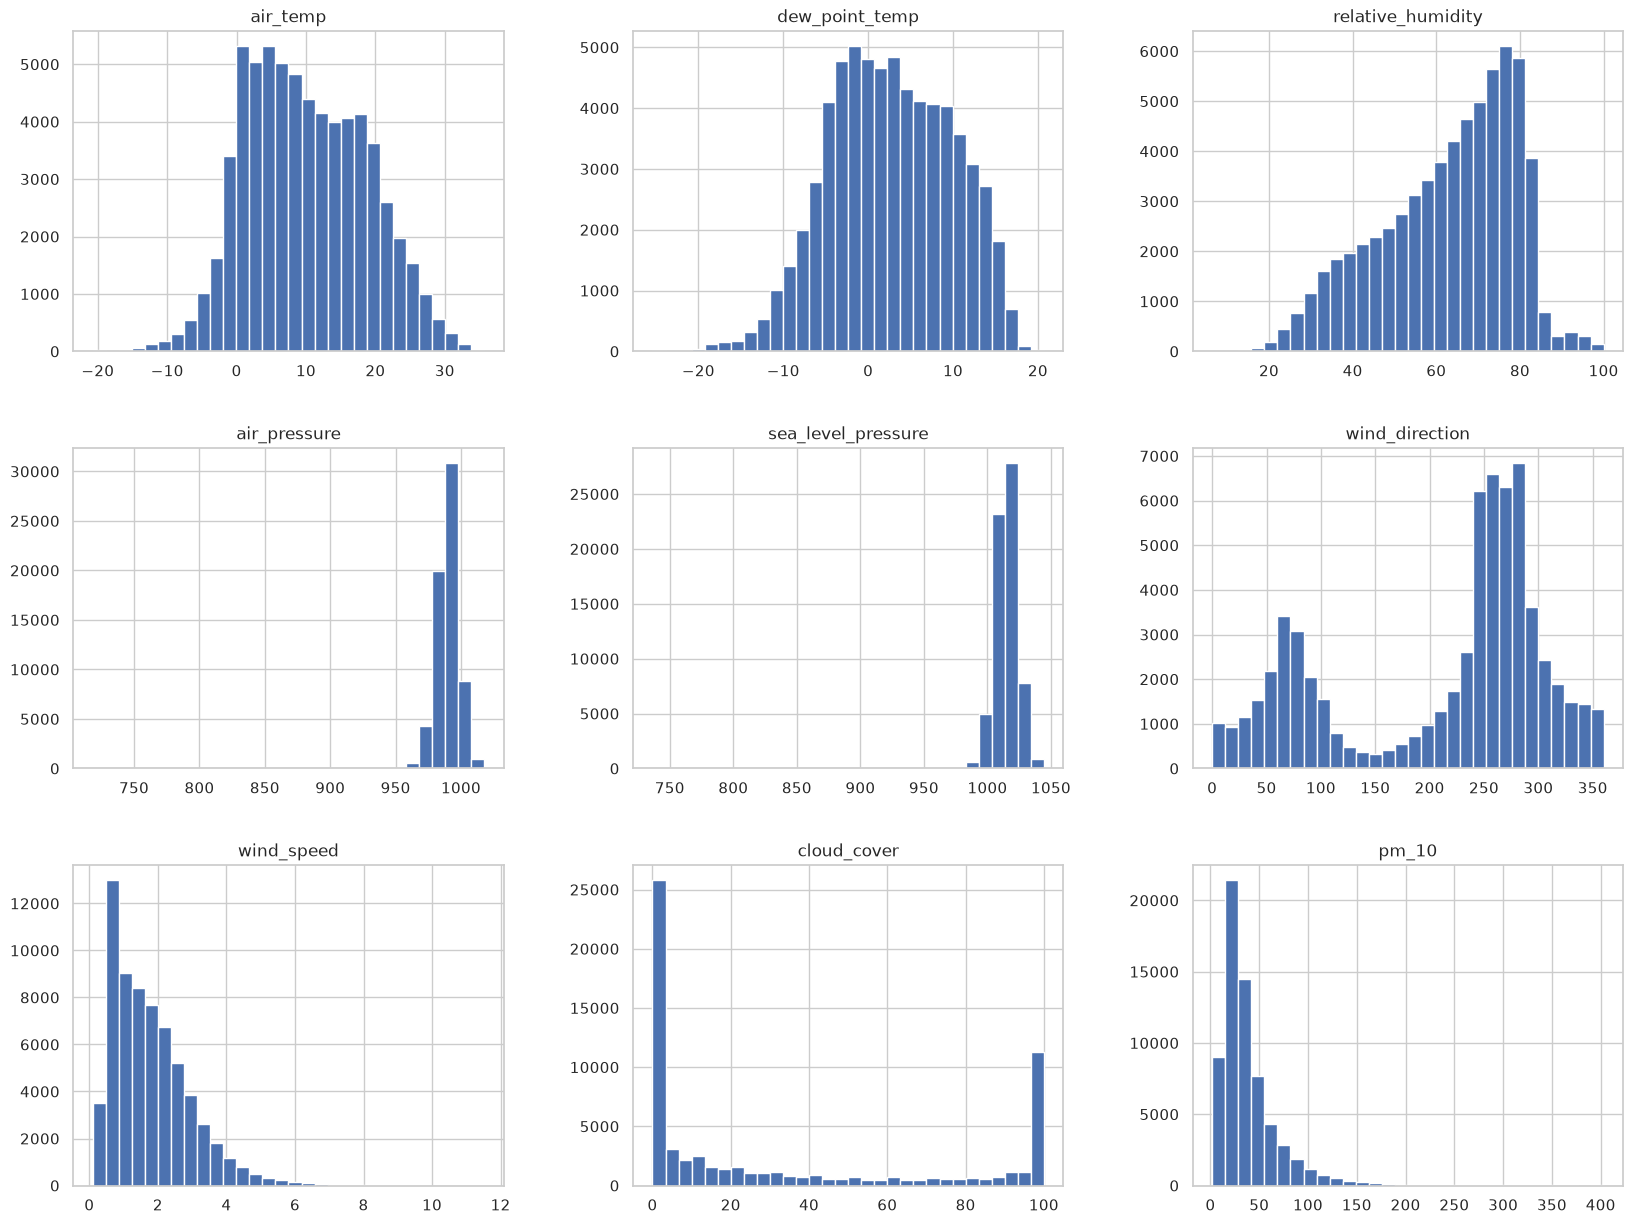

In [21]:
data[numeric_cols].hist(figsize=(20, 15), bins=30)